# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Luarez, Karl Andrei
- _Student No._: 2024-12430
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

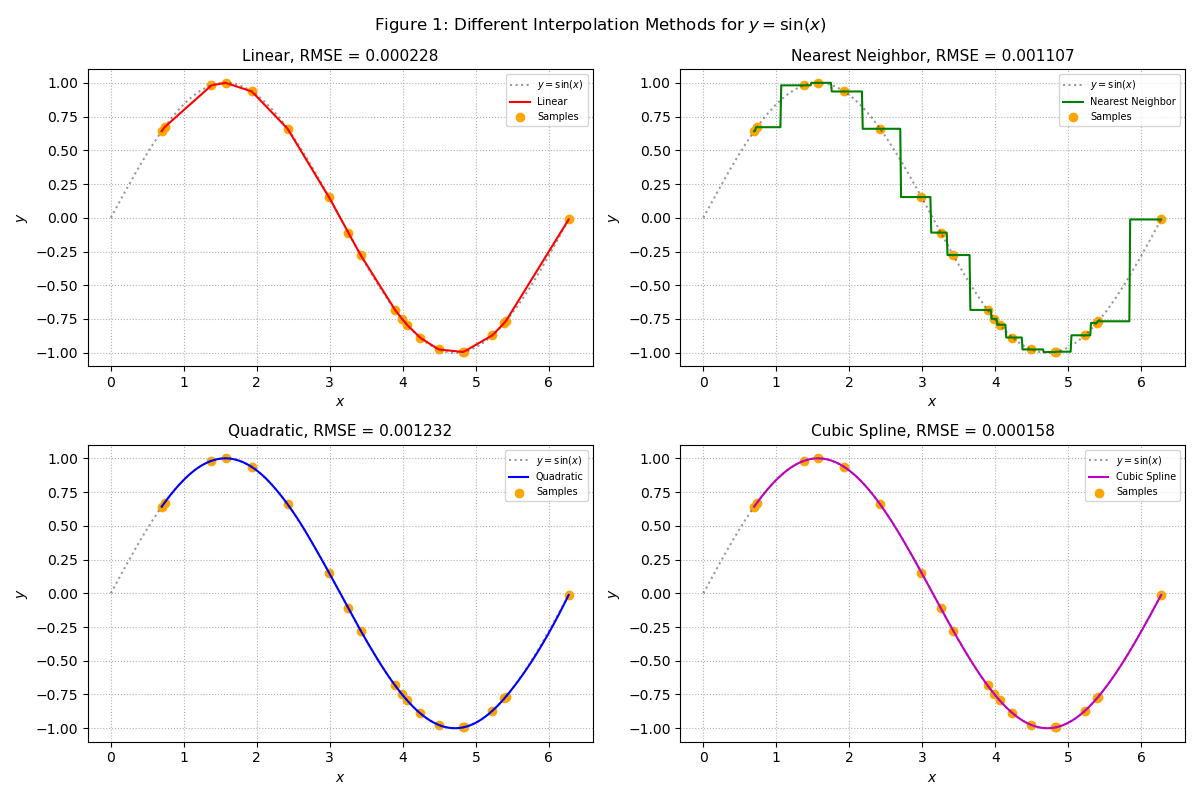
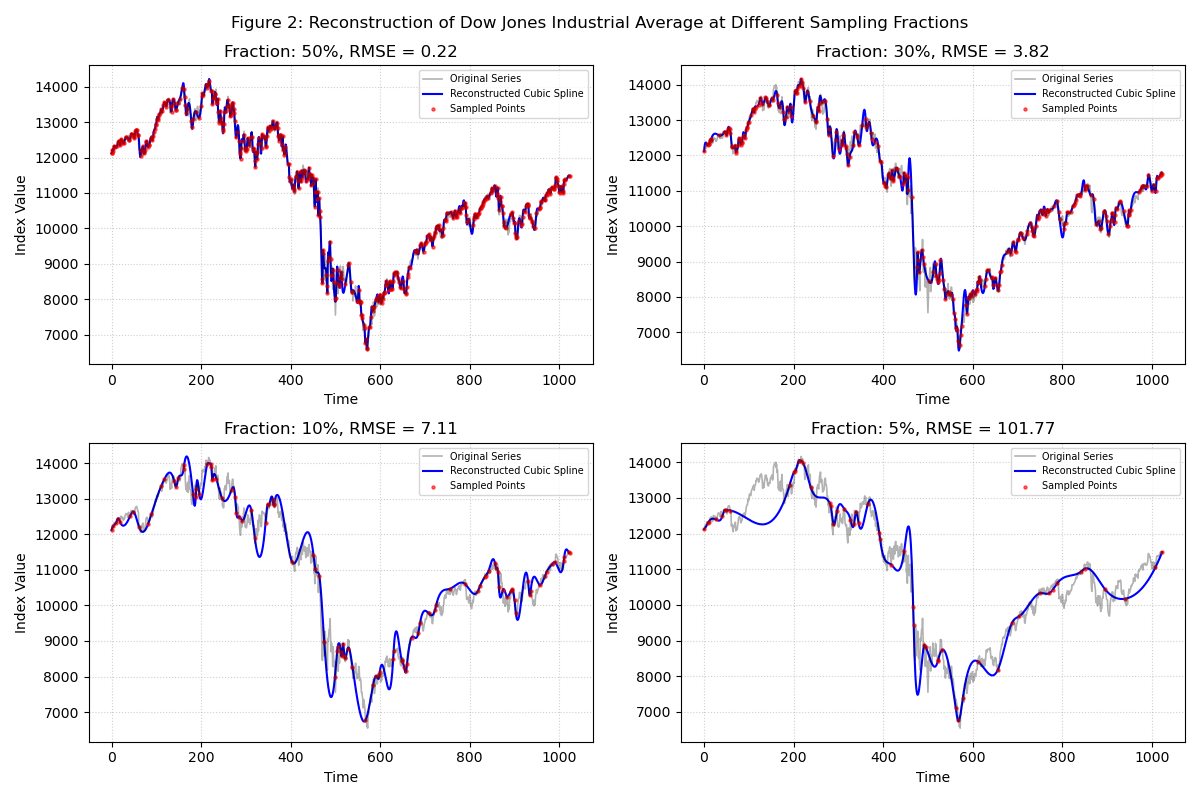

### Report discussion

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

The continuous Cubic Spline and quadratic interpolation is more accurate than the linear method which has "clips and breaks" in the function and the nearest neighbour which has jump discontinuities, both having a slightly larger root mean square error (RMSE). However, on the real-world data the lower order interpolation methods outperform the cubic and quadratic methods due to overshooting at sparser nodes.

**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

Figure 2 shows that the root mean square error increases as sampling fraction decreases. Consequently, the RMSE still remain relatively low for sampling fractions up to 30%, but the 10% sampling fraction seems to smoothen the noise from the original series while at 5% sampling level introduces drastic overshoots which brings the error to 107.11
### Other comments
- EDIT ME
- A self-reflection can be placed here. This portion is not graded.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

In [2]:
x_vals = np.linspace(0,2*np.pi,1000)
sample_size = 20

In [3]:
toy_func = lambda x: np.sin(x)

x_sample = np.sort(np.random.choice(x_vals, sample_size, replace=False))
y_sample = toy_func(x_sample)

In [4]:
# Creating a dictionary of different interpolation methods (func, color)
methods = {
    'Linear': (interpolate.interp1d(x_sample, y_sample, kind='linear'), 'r'),
    'Nearest Neighbor': (interpolate.interp1d(x_sample, y_sample, kind='nearest'), 'g'),
    'Quadratic': (interpolate.interp1d(x_sample, y_sample, kind='quadratic'), 'b'),
    'Cubic Spline': (interpolate.CubicSpline(x_sample, y_sample), 'm')
}
methods_list = list(methods.items())

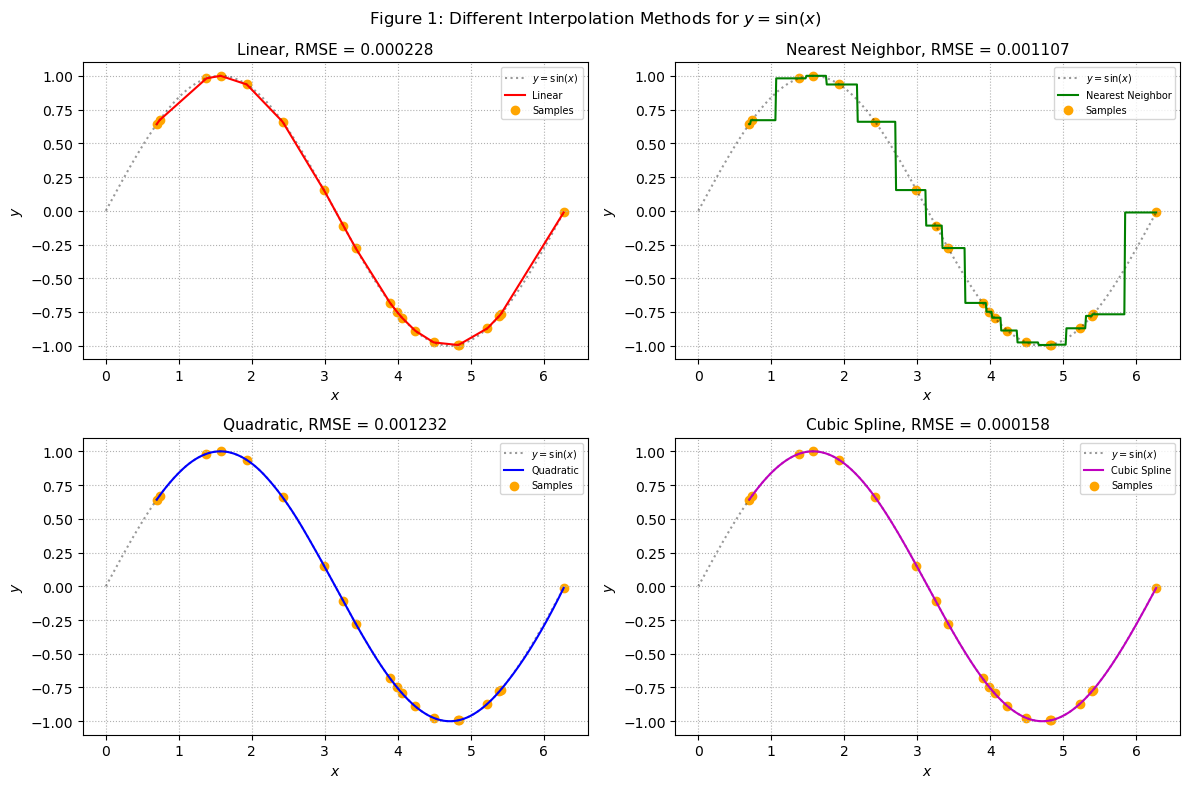

In [18]:
# Creating plots to compare different interpolation methods
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
fig_coords = [(0,0), (0,1), (1,0), (1,1)]
x_sorted = np.linspace(x_sample.min(), x_sample.max(), 500) # arrange in increasing order

for i, (row, col) in enumerate(fig_coords):
    label, (y_interp, color) = methods_list[i]
    yinterp = y_interp(x_sorted)
    rmse = np.sqrt(np.mean((toy_func(x_sorted))-yinterp)**2)
    
    ax = axs[row, col]
    ax.plot(x_vals, toy_func(x_vals), 'k:', label='$y=\sin(x)$', alpha=0.4)
    ax.plot(x_sorted, y_interp(x_sorted), label=label, color=color)
    ax.scatter(x_sample, y_sample, color='orange', label='Samples')
    ax.set_title(f'{label}, RMSE = {rmse:.6f}', fontsize=11)
    ax.grid(True, linestyle=':')
    ax.legend(loc='upper right', fontsize='7')
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
fig.suptitle('Figure 1: Different Interpolation Methods for $y = \sin(x)$')
fig.tight_layout()
plt.savefig("Figures/Exercise 9 Figure 1.png")
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [6]:
# !wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [7]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

In [8]:
filepath = "dow.txt"
dowjones = np.loadtxt(filepath)

N = len(dowjones)
time_i = np.arange(N)

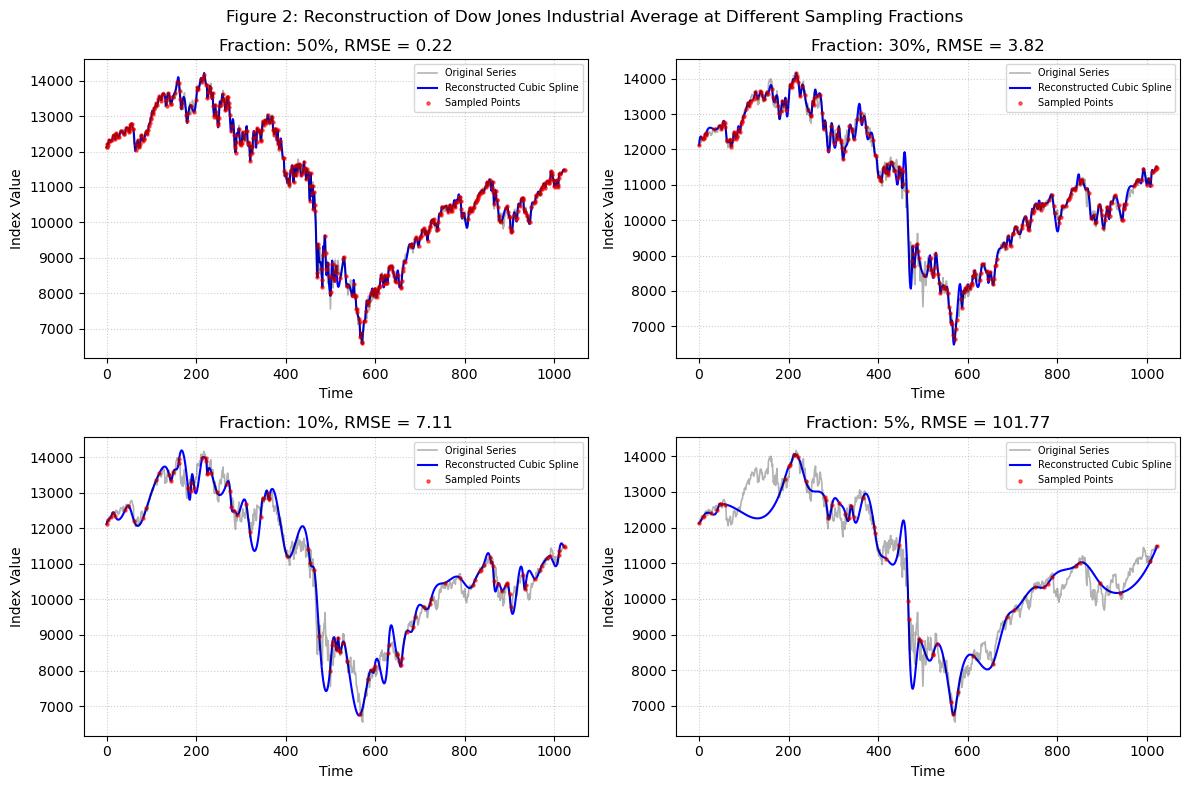

In [9]:
sampling_frac = [0.50, 0.30, 0.10, 0.05]

fig2, axs2 = plt.subplots(2, 2, figsize=(12,8))

for i, frac in enumerate(sampling_frac):
    n_sample = int(N*frac)
    sample_i = np.sort(np.random.choice(N, n_sample, replace=False))
    # include the endpoints of the data set
    if 0 not in sample_i: 
        sample_i = np.insert(sample_i,0,0)
    if (N-1) not in sample_i:
        sample_i = np.append(sample_i, N-1)
    time_sample = sample_i
    index_sample = dowjones[sample_i]

    # Cubic Spline reconstruction
    cubic = interpolate.CubicSpline(time_sample, index_sample)
    y_cubic = cubic(time_i)
    rmse = np.sqrt(np.mean(dowjones - y_cubic)**2) #taking the root mean square error
    
    row, col = fig_coords[i]
    ax = axs2[row, col]
    ax.plot(time_i, dowjones, 'k-', zorder=3, alpha=0.3, linewidth=1.2, label='Original Series')
    ax.plot(time_i, y_cubic, 'b-', zorder=2, linewidth=1.5, label='Reconstructed Cubic Spline',)
    ax.scatter(time_sample, index_sample, zorder=2, color='red', s=5, alpha=0.6, label='Sampled Points')
    ax.set_title(f'Fraction: {int(frac * 100)}%, RMSE = {rmse:.2f}')
    ax.set_xlabel('Time')
    ax.set_ylabel('Index Value')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper right', fontsize=7)

fig2.suptitle('Figure 2: Reconstruction of Dow Jones Industrial Average at Different Sampling Fractions')
plt.tight_layout()
plt.savefig("Figures/Exercise 9 Figure 2.png")
plt.show()

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

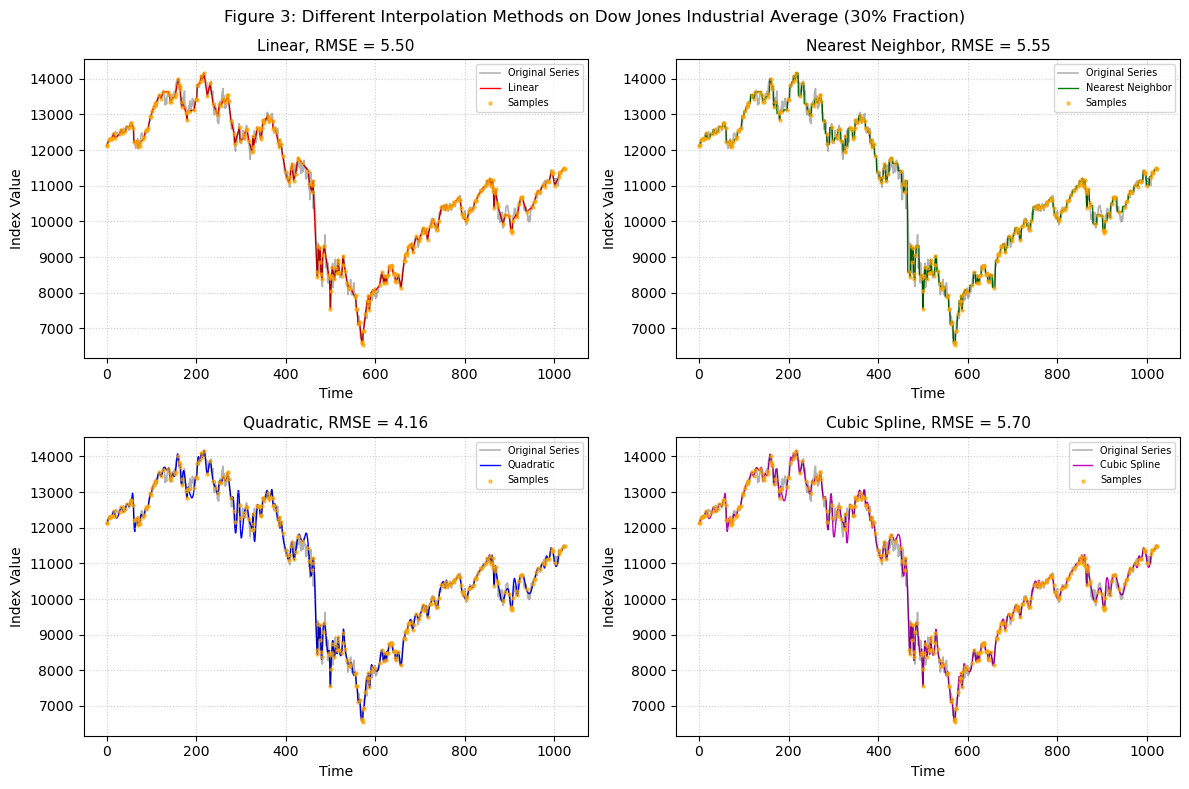

In [15]:
n_sample = int(N*0.30) #30%
sample_i = np.sort(np.random.choice(N, n_sample, replace=False))
if 0 not in sample_i:
    sample_i = np.insert(sample_i,0,0)
if (N-1) not in sample_i:
    sample_i = np.append(sample_i, N-1)
time_sample = sample_i
index_sample = dowjones[sample_i]

methods_realworld = {
    'Linear': (interpolate.interp1d(time_sample, index_sample, kind='linear'), 'r'),
    'Nearest Neighbor': (interpolate.interp1d(time_sample, index_sample, kind='nearest'), 'g'),
    'Quadratic': (interpolate.interp1d(time_sample, index_sample, kind='quadratic'), 'b'),
    'Cubic Spline': (interpolate.CubicSpline(time_sample, index_sample), 'm')
}
methods_list_realworld = list(methods_realworld.items())

# Plotting
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

for i, (row, col) in enumerate(fig_coords):
    label, (y_realworld, color) = methods_list_realworld[i]
    yrealworld = y_realworld(time_i)
    rmse = np.sqrt(np.mean(dowjones - yrealworld)**2) # RMSE

    
    ax = axs[row, col]
    ax.plot(time_i, dowjones, 'k-', zorder=2, alpha=0.3, linewidth=1.2, label='Original Series')
    ax.plot(time_i, yrealworld, zorder=1, linewidth=1.0, label=label, color=color)
    ax.scatter(time_sample, index_sample, zorder=3, color='orange', s=5, alpha=0.6, label='Samples')
    ax.set_title(f'{label}, RMSE = {rmse:.2f}', fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper right', fontsize='7')
    ax.set_xlabel('Time')
    ax.set_ylabel('Index Value')

fig.suptitle(f'Figure 3: Different Interpolation Methods on Dow Jones Industrial Average (30% Fraction)')
fig.tight_layout()
plt.savefig("Figures/Exercise 9 Figure 3.png")
plt.show()

### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---

I used the scipy.interpolate package to interpolate the data using the a dictionary i created of the different methods to avoid duplicating the code and used iterations to produce the subplots. In choosing the sample, I used np.random.choice() and sorted the data in increasing order for the y=sin(x) curve fitting and made sure I included the end points for interpolations involving the Dow Jones Industrial Average. For Problem 2 and 3, I computed the root mean square error to measure how much the curve fitting model deviates from the actual series.